---
## 📦 Cellule 1 — Installation

In [4]:
!pip install -q mediapipe>=0.10.14 kagglehub scipy scikit-learn tqdm matplotlib seaborn
!pip install -q torch torchvision torchaudio
!pip install -q torch_geometric

# Récupérer la version exacte de torch pour les wheel compatibles
import torch
TORCH_VER = torch.__version__.split('+')[0]


In [5]:
print(TORCH_VER)


2.6.0


In [6]:
import torch; print(torch.__version__)

2.6.0+cu124


In [7]:
pip uninstall torch torchvision torchaudio -y

Found existing installation: torch 2.6.0+cu124
Uninstalling torch-2.6.0+cu124:
  Successfully uninstalled torch-2.6.0+cu124
Found existing installation: torchvision 0.21.0+cu124
Uninstalling torchvision-0.21.0+cu124:
  Successfully uninstalled torchvision-0.21.0+cu124
Found existing installation: torchaudio 2.6.0+cu124
Uninstalling torchaudio-2.6.0+cu124:
  Successfully uninstalled torchaudio-2.6.0+cu124
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [8]:
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement torch (from versions: none)
ERROR: No matching distribution found for torch


In [9]:
!pip install torch_geometric -f https://data.pyg.org/whl/torch-2.2.0.html

Looking in links: https://data.pyg.org/whl/torch-2.2.0.html


In [10]:
!pip install -q torch_scatter torch_sparse -f https://data.pyg.org/whl/torch-{TORCH_VER}.html

  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [23 lines of output]
      Traceback (most recent call last):
        File "C:\Users\Team1\Desktop\BOUSBAA\env_Bousbaa\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 389, in <module>
          main()
          ~~~~^^
        File "C:\Users\Team1\Desktop\BOUSBAA\env_Bousbaa\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\Team1\Desktop\BOUSBAA\env_Bousbaa\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 143, in get_requires_for_build_wheel
          return hook(config_settings)
        File "C:\Users\Team1\AppData\Local\Temp\pip-build-env-nk_ey76o\overlay\Lib\site-packages\setuptools\build_meta.py", line 

In [11]:
import importlib
print('\n🔍 Vérification :')
for pkg in ['mediapipe','kagglehub','torch','torch_geometric','scipy','sklearn','tqdm']:
    ok = importlib.util.find_spec(pkg) is not None
    print(f'  {"✅" if ok else "❌"} {pkg}')

import mediapipe as mp
major, minor = map(int, mp.__version__.split('.')[:2])
assert (major, minor) >= (0, 10), '❌ mediapipe >= 0.10.9 requis'
print(f'\n  mediapipe {mp.__version__} — Tasks API disponible ✅')

import torch
print(f'  torch {torch.__version__} — CUDA: {torch.cuda.is_available()} ✅')


🔍 Vérification :
  ✅ mediapipe
  ✅ kagglehub
  ✅ torch
  ✅ torch_geometric
  ✅ scipy
  ✅ sklearn
  ✅ tqdm

  mediapipe 0.10.33 — Tasks API disponible ✅
  torch 2.6.0+cu124 — CUDA: True ✅


---
## 🔗 Cellule 2 — Google Drive

In [12]:
#from google.colab import drive
#drive.mount('/content/mydrive')

In [13]:
import os, json

# ── Chemins drive ──────────────────────────────────────────────
# /kaggle/input    → datasets ajoutés via "Add Data"

DRIVE_ROOT   = 'DATASET'
CACHE_DIR    = os.path.join(DRIVE_ROOT, 'cache')
MODEL_DIR    = os.path.join(DRIVE_ROOT, 'models')
LOG_DIR      = os.path.join(DRIVE_ROOT, 'logs')

# Ensure the base project directory exists first
try:
    os.makedirs(DRIVE_ROOT, exist_ok=True)
except OSError as e:
    if os.path.isdir(DRIVE_ROOT):
        print(f"Warning: '{DRIVE_ROOT}' already exists but os.makedirs raised an error. Proceeding.")
    else:
        print(f"Error creating base directory '{DRIVE_ROOT}': {e}. Subsequent operations may fail.")
        # If the base directory cannot be created, it's critical.
        # Re-raise the exception or handle appropriately if you want to stop execution.
        raise

# Now create subdirectories within the ensured base directory
for d in [CACHE_DIR, MODEL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

CACHE_GRAPHS = os.path.join(CACHE_DIR, 'graphs_list.pkl')
CACHE_LABELS = os.path.join(CACHE_DIR, 'labels_array.pkl')
CACHE_META   = os.path.join(CACHE_DIR, 'meta.json')

def cache_exists():
    return os.path.isfile(CACHE_GRAPHS)

print(f'📁 Working dir : {DRIVE_ROOT}')
print(f'📁 Cache dir   : {CACHE_DIR}')

if cache_exists():
    print(f'\n⚡ Cache détecté')
    if os.path.isfile(CACHE_META):
        with open(CACHE_META) as f:
            m = json.load(f)
        print(f'   Méta : {m.get("n_graphs")} graphes — {m.get("timestamp")}')
else:
    print('\nℹ️  Aucun cache trouvé.')

📁 Working dir : DATASET
📁 Cache dir   : DATASET\cache

⚡ Cache détecté
   Méta : 17072 graphes — 2026-04-19 05:12:24


In [14]:
#from google.colab import drive
#drive.mount('/content/drive')

---
## 🤖 Cellule 3 — Téléchargement `face_landmarker.task`
> Modèle officiel MediaPipe float16 (Google Storage).  
> Stocké sur Drive → **une seule fois**, même après redémarrage Colab.

In [15]:
import os, shutil, urllib.request

# ── Chemins adaptés à Windows ─────────────────────────────────────────────────
MODEL_TASK_DRIVE = os.path.join(DRIVE_ROOT, 'face_landmarker.task')
MODEL_TASK_LOCAL = os.path.join(DRIVE_ROOT, 'face_landmarker_local.task')  # chemin local valide
MODEL_URL = (
    'https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task'
)

# ── Téléchargement (urllib, compatible Windows) ───────────────────────────────
if not os.path.isfile(MODEL_TASK_DRIVE):
    print('📥 Téléchargement de face_landmarker.task ...')

    def _progress(block_num, block_size, total_size):
        downloaded = block_num * block_size
        pct = min(downloaded / total_size * 100, 100) if total_size > 0 else 0
        print(f'\r   {pct:.1f}%  ({downloaded/1e6:.1f} / {total_size/1e6:.1f} Mo)', end='')

    os.makedirs(DRIVE_ROOT, exist_ok=True)  # crée le dossier si absent
    urllib.request.urlretrieve(MODEL_URL, MODEL_TASK_DRIVE, reporthook=_progress)
    print(f'\n✅ Sauvegardé : {MODEL_TASK_DRIVE}')
else:
    print(f'✅ Déjà présent ({os.path.getsize(MODEL_TASK_DRIVE)/1e6:.1f} Mo).')

# ── Copie locale (optionnel sur Windows, Drive n'existe pas) ──────────────────
if MODEL_TASK_LOCAL != MODEL_TASK_DRIVE and not os.path.isfile(MODEL_TASK_LOCAL):
    shutil.copy(MODEL_TASK_DRIVE, MODEL_TASK_LOCAL)

print(f'\n🧠 Modèle prêt : {MODEL_TASK_LOCAL}')
print(f'   Taille : {os.path.getsize(MODEL_TASK_LOCAL)/1e6:.1f} Mo')

✅ Déjà présent (3.8 Mo).

🧠 Modèle prêt : DATASET\face_landmarker_local.task
   Taille : 3.8 Mo


---
## 📥 Cellule 4 — Téléchargement RAF-DB (kagglehub)
> `kagglehub` gère son propre cache (`~/.cache/kagglehub/`).  
> Au 2ᵉ appel, le chemin est retourné **sans re-télécharger**.

In [16]:
import kagglehub
# Download the specific dataset requested
DATASET_PATH = kagglehub.dataset_download("jvageesh11/rafdb-balanced-dataset")
print(f'✅ RAF-DB dataset path set to: {DATASET_PATH}')

✅ RAF-DB dataset path set to: C:\Users\Team1\.cache\kagglehub\datasets\jvageesh11\rafdb-balanced-dataset\versions\1


---
## ⚙️ Cellule 5 — Hyperparamètres (Tables 1 & 2 du papier)

In [17]:
import os

# ── Chercher le fichier label avec des critères élargis ────────────────────────
print('🔍 Fichiers à la racine du dataset :')
for f in os.listdir(DATASET_PATH):
    full = os.path.join(DATASET_PATH, f)
    if os.path.isfile(full):
        print(f'  📄 {f}  ({os.path.getsize(full):,} bytes)')
    else:
        print(f'  📁 {f}/')

# Chercher récursivement tous les .txt et .csv
print('\n🔍 Tous les fichiers .txt / .csv dans le dataset :')
for root, dirs, files in os.walk(DATASET_PATH):
    for f in files:
        if f.lower().endswith(('.txt', '.csv', '.json')):
            full = os.path.join(root, f)
            print(f'  📄 {full}  ({os.path.getsize(full):,} bytes)')

🔍 Fichiers à la racine du dataset :
  📁 test/
  📁 train/

🔍 Tous les fichiers .txt / .csv dans le dataset :


In [ ]:
CFG = dict(
    img_size                 = 224,
    min_detection_confidence = 0.5,
    in_channels              = 10,               # ← Mis à jour à 10 pour les graphes duals (barycentres + géométrie)

    # Architecture plus large
    gcn_layer_sizes          = [32, 64, 128, 256],
    dense_units              = 256,
    n_classes                = 7,

    # Régularisation
    dropout                  = 0.5,              # ← augmenté
    weight_decay             = 1e-4,             # ← nouveau

    # Training
    learning_rate            = 3e-4,             # ← réduit (1e-3 → 3e-4)
    batch_size               = 32,               # ← augmenté (10 → 32)
    epochs                   = 200,               # ← augmenté
    patience                 = 15,
    #k_folds                  = 10,

    model_dir = './models_dual',
    log_dir   = './logs_dual',
)
RAF_LABELS_ORIG = {
    1: 'Surprise', 2: 'Fear', 3: 'Disgust',
    4: 'Happiness', 5: 'Sadness', 6: 'Anger', 7: 'Neutral'
}
EMOTIONS_0_indexed = {k-1: v for k, v in RAF_LABELS_ORIG.items()}
print('✅ Config updated for 10 channels (dual graph).')


✅ Config updated for 10 channels (dual graph).


---
## 🤖 Cellule 6 — Initialisation FaceLandmarker (Tasks API)

| | Ancien `face_mesh` | Nouveau Tasks API |
|---|---|---|
| Import | `mp.solutions.face_mesh` | `mediapipe.tasks.python.vision` |
| Classe | `FaceMesh()` | `FaceLandmarker.create_from_options()` |
| Landmarks | 468 | **478** (+ iris) |
| Input | `np.ndarray` RGB | `mp.Image(SRGB, data=...)` |
| Blendshapes | ✗ | ✓ optionnel |

In [19]:
import mediapipe as mp
from mediapipe.tasks import python          # BaseOptions
from mediapipe.tasks.python import vision   # FaceLandmarker, RunningMode
import numpy as np, cv2


def make_face_landmarker(model_path: str, min_conf: float = 0.5):
    """
    Instancie un FaceLandmarker en mode IMAGE (synchrone).
    Réutilise la même instance pour toutes les images du dataset.
    """
    base_opts = python.BaseOptions(model_asset_path=model_path)
    opts = vision.FaceLandmarkerOptions(
        base_options                      = base_opts,
        running_mode                      = vision.RunningMode.IMAGE,
        num_faces                         = 1,
        min_face_detection_confidence     = min_conf,
        min_face_presence_confidence      = min_conf,
        min_tracking_confidence           = min_conf,
        output_face_blendshapes           = False,   # non requis
        output_facial_transformation_matrixes = False,
    )
    return vision.FaceLandmarker.create_from_options(opts)


# Instance globale — créée UNE FOIS, partagée partout
FACE_LANDMARKER = make_face_landmarker(
    model_path = MODEL_TASK_LOCAL,
    min_conf   = CFG['min_detection_confidence']
)

print('✅ FaceLandmarker prêt (Tasks API)')
print(f'   Modèle  : face_landmarker.task (float16)')
print(f'   Mode    : IMAGE (synchrone)')
print(f'   Conf.   : {CFG["min_detection_confidence"]}')

# Smoke test
_blank = np.zeros((224, 224, 3), dtype=np.uint8)
_r     = FACE_LANDMARKER.detect(
    mp.Image(image_format=mp.ImageFormat.SRGB, data=_blank)
)
print(f'\n   Smoke test (image noire) : {len(_r.face_landmarks)} visage(s) → OK')
del _blank, _r

✅ FaceLandmarker prêt (Tasks API)
   Modèle  : face_landmarker.task (float16)
   Mode    : IMAGE (synchrone)
   Conf.   : 0.5

   Smoke test (image noire) : 0 visage(s) → OK


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.utils import to_networkx
import cv2
import numpy as np
import os

def visualize_image_and_graph(
    image_path: str,
    landmarker,
    img_size: int,
    build_graph_func
):
    """
    Visualise l'image avec les landmarks et le graphe résultant (primal ou dual selon build_graph_func).

    Args:
        image_path: Chemin vers l'image.
        landmarker: Instance de FaceLandmarker.
        img_size: Taille de l'image (pour le redimensionnement et la mise à l'échelle des landmarks).
        build_graph_func: La fonction à utiliser pour construire le graphe à partir des landmarks.
    """
    img_orig = cv2.imread(image_path)
    if img_orig is None:
        print(f"❌ Impossible de charger l'image : {image_path}")
        return

    img_orig_rgb = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
    img_display = cv2.resize(img_orig_rgb, (img_size, img_size))

    # Extraire les landmarks (déjà mis à l'échelle dans extract_3d_landmarks)
    landmarks_3d = extract_3d_landmarks(image_path, landmarker, img_size)
    if landmarks_3d is None:
        print(f"❌ Pas de landmarks détectés pour {os.path.basename(image_path)}")
        return

    # Construire le graphe (peut être primal ou dual selon build_graph_func)
    # Renommé `graph_data` pour être générique
    graph_data = build_graph_func(landmarks_3d)
    if graph_data is None:
        print(f"❌ Impossible de construire le graphe pour {os.path.basename(image_path)}")
        return

    # ================================================
    # 1. Visualisation de l'image avec les landmarks
    # ================================================
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    axes[0].imshow(img_display)
    axes[0].set_title(f"Image avec Landmarks (ID: {os.path.basename(image_path)})")
    axes[0].axis('off')

    # Dessiner les landmarks 2D sur l'image
    # Les landmarks_3d contiennent déjà les coordonnées mises à l'échelle (x,y) en pixels
    axes[0].scatter(landmarks_3d[:, 0], landmarks_3d[:, 1], s=5, c='red', alpha=0.7)

    # ================================================
    # 2. Visualisation du Graphe (Dual ou Primal)
    # ================================================
    nx_graph = to_networkx(graph_data, to_undirected=True) # Convertir en graphe NetworkX

    # Déterminer si c'est un graphe primal ou dual pour les titres et prints
    is_dual = build_graph_func == build_dual_graph_from_landmarks
    graph_type_str = "Dual" if is_dual else "Primal"
    node_description = "Barycenters" if is_dual else "Landmarks"
    edge_description = "Dual Edges" if is_dual else "Delaunay"

    print(f"\nVisualisation du graphe {graph_type_str} pour l'image : {os.path.basename(image_path)}")
    print(f"Nombre de nœuds ({node_description}) : {nx_graph.number_of_nodes()}")
    print(f"Nombre d'arêtes ({edge_description}) : {nx_graph.number_of_edges()}")
    print(f"Features par nœud : {graph_data.x.shape[1]}")

    # Utiliser les 2 premières dimensions des features des nœuds du graphe
    # comme positions pour la visualisation. Pour le graphe dual, ce sont les barycentres.
    # Pour le graphe primal, ce seraient les (x,y) des landmarks.
    pos = {i: (graph_data.x[i, 0].item(), graph_data.x[i, 1].item()) for i in range(graph_data.num_nodes)}

    nx.draw_networkx_nodes(nx_graph, pos, node_size=20, node_color='skyblue', ax=axes[1])
    nx.draw_networkx_edges(nx_graph, pos, alpha=0.5, ax=axes[1])
    # Optionnel: dessiner les labels des nœuds si besoin (peut surcharger)
    # nx.draw_networkx_labels(nx_graph, pos, font_size=4, font_color='black', ax=axes[1])
    axes[1].set_title(f"{graph_type_str} Graph (Nodes = {node_description}, Edges = {edge_description})")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

---
## 🔬 Cellule 7 — Fonctions de preprocessing
> image → landmarks (Tasks API) → Delaunay

In [21]:
from scipy.spatial import Delaunay
import torch
from torch_geometric.data import Data
import numpy as np

def build_dual_graph_from_landmarks(landmarks_3d: np.ndarray):
    """
    Construit un graphe DUAL correct :

    - Nœuds = triangles (faces) de Delaunay
    - Arêtes = triangles adjacents (partagent une arête)
    - Features = barycentre + géométrie locale (10 features)
    """

    if landmarks_3d is None or len(landmarks_3d) < 3:
        return None

    points_2d = landmarks_3d[:, :2]

    try:
        tri = Delaunay(points_2d)
    except:
        return None

    triangles = tri.simplices  # (T, 3)
    num_triangles = len(triangles)

    # ==============================
    # 1. Features des noeuds (triangles)
    # ==============================
    node_features = []

    for tri_indices in triangles:
        pts = landmarks_3d[tri_indices]  # (3, 3)

        # barycentre
        centroid = pts.mean(axis=0)

        # longueurs des arêtes
        e1 = np.linalg.norm(pts[0] - pts[1])
        e2 = np.linalg.norm(pts[1] - pts[2])
        e3 = np.linalg.norm(pts[2] - pts[0])

        # surface (aire triangle)
        area = 0.5 * np.linalg.norm(np.cross(pts[1] - pts[0], pts[2] - pts[0]))

        # normal vector
        normal = np.cross(pts[1] - pts[0], pts[2] - pts[0])
        normal = normal / (np.linalg.norm(normal) + 1e-8)

        # feature vector (10 dims: barycenter x,y,z, 3 edge lengths, area, normal x,y,z)
        feat = np.concatenate([
            centroid,        # 3
            [e1, e2, e3],    # 3
            [area],          # 1
            normal           # 3
        ])

        node_features.append(feat)

    x = torch.tensor(np.array(node_features), dtype=torch.float)

    # ==============================
    # 2. Construction des arêtes (DUAL)
    # ==============================
    edges = set()

    # mapping arête → triangles
    edge_to_triangles = {}

    for i, tri_indices in enumerate(triangles):
        for j in range(3):
            edge = tuple(sorted([
                tri_indices[j],
                tri_indices[(j + 1) % 3]
            ]))

            if edge not in edge_to_triangles:
                edge_to_triangles[edge] = []
            edge_to_triangles[edge].append(i)

    # connecter triangles voisins
    for edge, tris in edge_to_triangles.items():
        if len(tris) == 2:
            t1, t2 = tris
            edges.add((t1, t2))
            edges.add((t2, t1))

    if len(edges) == 0:
        return None

    edge_index = torch.tensor(list(edges), dtype=torch.long).t().contiguous()

    # ==============================
    # 3. Création du graphe PyG
    # ==============================
    graph = Data(x=x, edge_index=edge_index)

    return graph

---
## 🏷️ Cellule 8 — Chargement des labels RAF-DB

In [23]:
import cv2
import mediapipe as mp
import numpy as np
from scipy.spatial import Delaunay
import torch
from torch_geometric.data import Data
from sklearn.neighbors import NearestNeighbors


def extract_3d_landmarks(image_path: str, landmarker, img_size: int = 224):
    """
    Extrait les 478 landmarks 3D via MediaPipe.
    """
    img = cv2.imread(image_path)
    if img is None:
        return None

    img = cv2.resize(img, (img_size, img_size))
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )

    result = landmarker.detect(mp_image)
    if not result.face_landmarks:
        return None

    return np.array(
        [[lm.x * img_size, lm.y * img_size, lm.z * img_size]
         for lm in result.face_landmarks[0]],
        dtype=np.float32
    )


def build_graph_from_landmarks(
    landmarks,
    method="delaunay",   # "delaunay" ou "knn"
    k=6,
    use_3d=True
):
    """
    Convertit des landmarks MediaPipe en graphe PyTorch Geometric.

    Args:
        landmarks: np.array shape (N, 3) ou (N, 2)
        method: "delaunay" ou "knn"
        k: nombre de voisins (si knn)
        use_3d: utiliser (x,y,z) ou seulement (x,y)

    Returns:
        Data: objet PyG (x, edge_index)
    """

    # =========================
    # 1. Features (nodes)
    # =========================
    if not use_3d:
        landmarks = landmarks[:, :2]

    x = torch.tensor(landmarks, dtype=torch.float)

    # =========================
    # 2. Construction des edges
    # =========================
    if method == "delaunay":
        # Delaunay triangulation requires at least 3 unique 2D points
        points_2d = landmarks[:, :2]
        if len(np.unique(points_2d, axis=0)) < 3:
            return None

        try:
            tri = Delaunay(points_2d)  # triangulation 2D
        except Exception:
            return None # Handle cases where Delaunay might fail for degenerate points

        edges = set()
        for simplex in tri.simplices:
            # Ensure simplex has valid indices
            if len(simplex) == 3:
                for i in range(3):
                    a = simplex[i]
                    b = simplex[(i + 1) % 3]
                    edges.add((min(a, b), max(a, b))) # Store as sorted tuple to avoid duplicates

        # Convert to directed edges for PyG
        final_edges = []
        for u, v in edges:
            final_edges.append((u, v))
            final_edges.append((v, u))

        if not final_edges:
            return None
        edge_index = torch.tensor(list(final_edges), dtype=torch.long).t().contiguous()

    elif method == "knn":
        if len(landmarks) < k + 1: # Need at least k+1 points for k-NN
            return None

        nbrs = NearestNeighbors(n_neighbors=k).fit(landmarks)
        _, indices = nbrs.kneighbors(landmarks)

        edges = set()
        for i in range(len(landmarks)):
            for j_idx in indices[i]:
                j = j_idx # indices directly give the index
                if i != j:
                    edges.add((min(i, j), max(i, j))) # Store as sorted tuple

        # Convert to directed edges for PyG
        final_edges = []
        for u, v in edges:
            final_edges.append((u, v))
            final_edges.append((v, u))

        if not final_edges:
            return None
        edge_index = torch.tensor(list(final_edges), dtype=torch.long).t().contiguous()

    else:
        raise ValueError("method doit être 'delaunay' ou 'knn'")

    # =========================
    # 3. Création du graphe
    # =========================
    data = Data(x=x, edge_index=edge_index)

    return data


# ── Test rapide ───────────────────────────────────────────────
print("✅ Nouvelle version de build_graph_from_landmarks chargée.")

_lm = np.random.rand(478, 3).astype(np.float32) * 224 # 478 landmarks 3D
_g = build_graph_from_landmarks(_lm, method="delaunay", use_3d=True)

if _g is not None:
    print(f"Nodes: {_g.num_nodes}")
    print(f"Edges: {_g.edge_index.shape[1]}")
    print(f"Features: {_g.x.shape[1]} (use_3d=True) ✅")
else:
    print("⚠️ Graphe non généré")

#Dual graph:_____________________________________________

print("\n✅ Nouvelle version de build_Dual_graph chargée.")

_dg = build_dual_graph_from_landmarks(_lm)

if _dg is not None:
    print(f"Nodes: {_dg.num_nodes}")
    print(f"Edges: {_dg.edge_index.shape[1]}")
    print(f"Features: {_dg.x.shape[1]} (use_3d=True) ✅")
else:
    print("⚠️ Graphe non généré")

✅ Nouvelle version de build_graph_from_landmarks chargée.
Nodes: 478
Edges: 2826
Features: 3 (use_3d=True) ✅

✅ Nouvelle version de build_Dual_graph chargée.
Nodes: 936
Edges: 2790
Features: 10 (use_3d=True) ✅


Searching for an image of class 'Surprise'...
Found image: train_00006_aligned.jpg (Index: 0)

Attempting to visualize dual graph for 'Surprise' image: train_00006_aligned.jpg

Visualisation du graphe Dual pour l'image : train_00006_aligned.jpg
Nombre de nœuds (Barycenters) : 919
Nombre d'arêtes (Dual Edges) : 1361
Features par nœud : 10


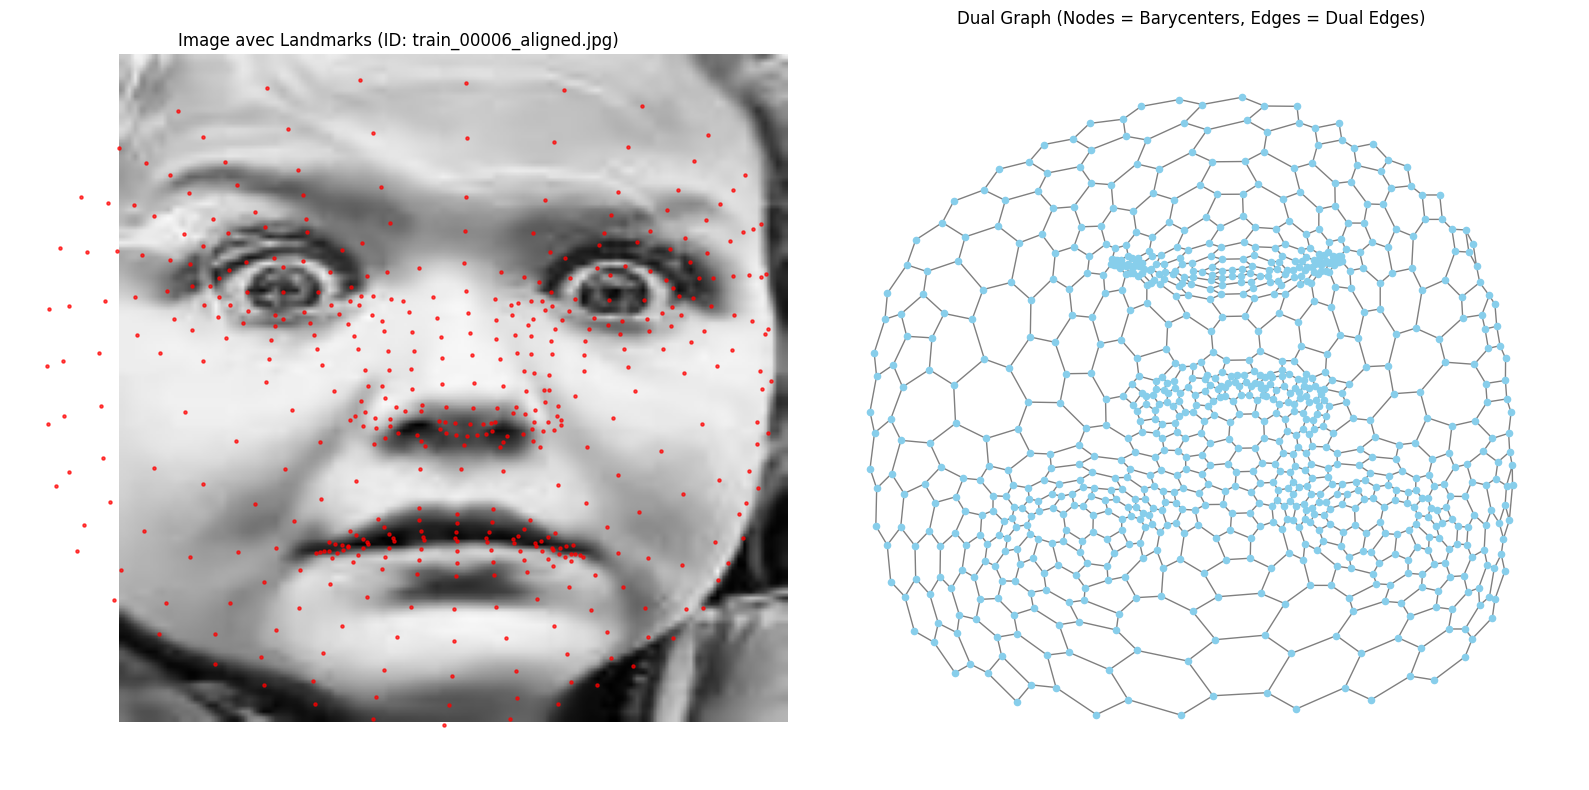

In [24]:
import os

# Find an image labeled 'Surprise' (label 1 in RAF_LABELS_ORIG)
happy_image_path = None
happy_label_id = 1 # 'Surprise' corresponds to label 1 in RAF_LABELS_ORIG

print(f"Searching for an image of class '{RAF_LABELS_ORIG[happy_label_id]}'...")

for i, (path, label) in enumerate(zip(image_paths, labels)):
    if label == happy_label_id:
        lm = extract_3d_landmarks(path, FACE_LANDMARKER, CFG['img_size'])
        if lm is None:
            # print(f"Skipping {os.path.basename(path)}: No landmarks detected.")
            continue
        G = build_dual_graph_from_landmarks(lm)
        if G is None:
            # print(f"Skipping {os.path.basename(path)}: Could not build dual graph.")
            continue
        happy_image_path = path
        print(f"Found image: {os.path.basename(happy_image_path)} (Index: {i})")
        break

if happy_image_path:
    print(f"\nAttempting to visualize dual graph for '{RAF_LABELS_ORIG[happy_label_id]}' image: {os.path.basename(happy_image_path)}")
    visualize_image_and_graph(
        image_path=happy_image_path,
        landmarker=FACE_LANDMARKER,
        img_size=CFG['img_size'],
        build_graph_func=build_dual_graph_from_landmarks # Use the dual graph builder
    )
else:
    print(f"\nCould not find a suitable '{RAF_LABELS_ORIG[happy_label_id]}' image to visualize.")
    print("Please ensure there are images of this class in your dataset and that landmark detection and dual graph building succeed for them.")

Searching for an image of class 'Happiness'...
Found image: train_00003_aligned.jpg (Index: 3000)

Attempting to visualize dual graph for 'Happiness' image: train_00003_aligned.jpg

Visualisation du graphe Dual pour l'image : train_00003_aligned.jpg
Nombre de nœuds (Barycenters) : 921
Nombre d'arêtes (Dual Edges) : 1365
Features par nœud : 10


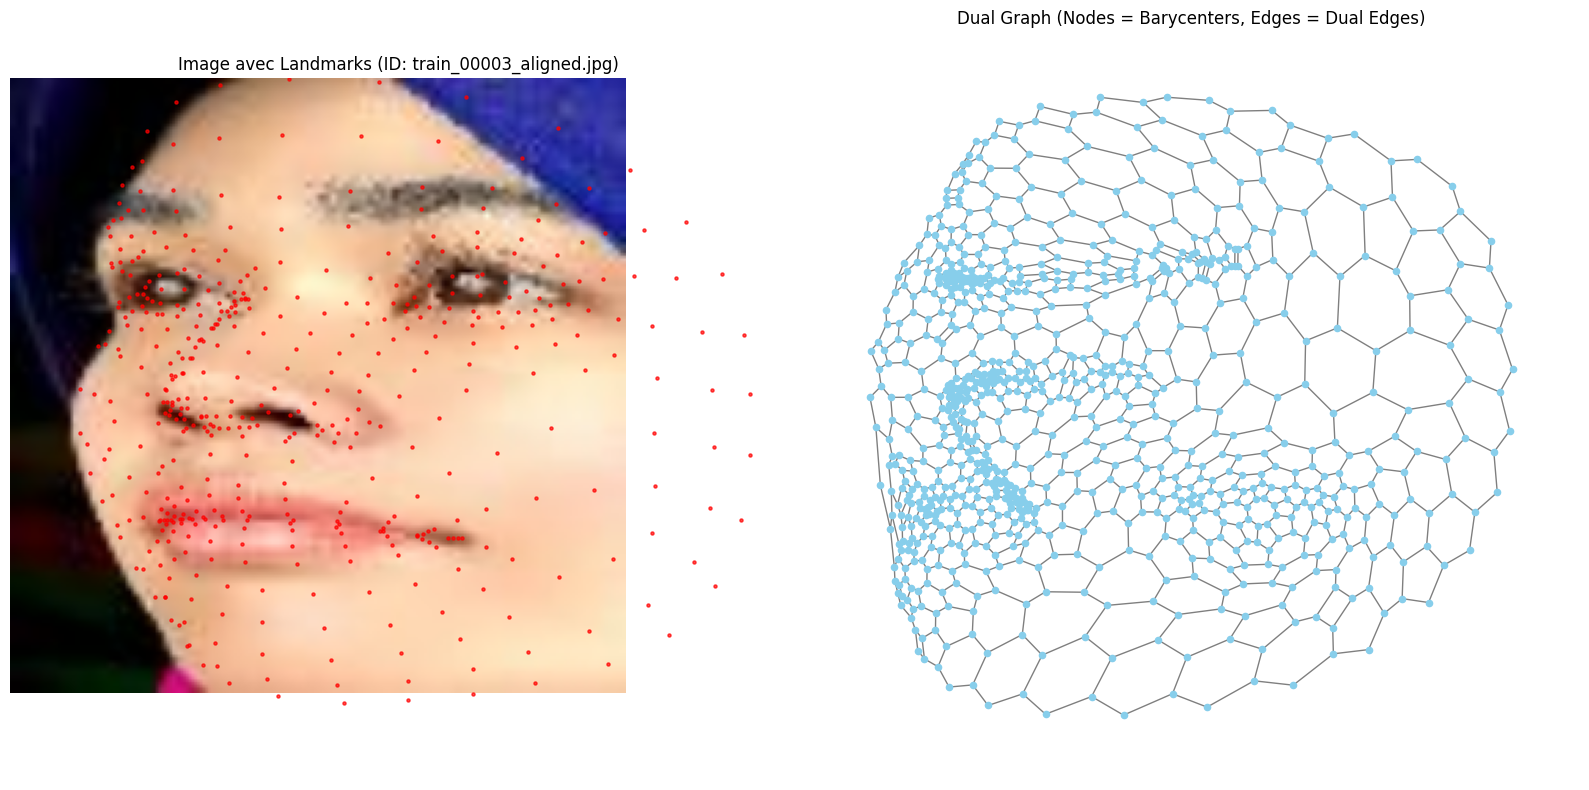

In [25]:
import os

# Find an image labeled 'Happiness' (label 4 in RAF_LABELS_ORIG)
happy_image_path = None
happy_label_id = 4 # 'Happiness' corresponds to label 4 in RAF_LABELS_ORIG

print(f"Searching for an image of class '{RAF_LABELS_ORIG[happy_label_id]}'...")

for i, (path, label) in enumerate(zip(image_paths, labels)):
    if label == happy_label_id:
        lm = extract_3d_landmarks(path, FACE_LANDMARKER, CFG['img_size'])
        if lm is None:
            # print(f"Skipping {os.path.basename(path)}: No landmarks detected.")
            continue
        G = build_dual_graph_from_landmarks(lm)
        if G is None:
            # print(f"Skipping {os.path.basename(path)}: Could not build dual graph.")
            continue
        happy_image_path = path
        print(f"Found image: {os.path.basename(happy_image_path)} (Index: {i})")
        break

if happy_image_path:
    print(f"\nAttempting to visualize dual graph for '{RAF_LABELS_ORIG[happy_label_id]}' image: {os.path.basename(happy_image_path)}")
    visualize_image_and_graph(
        image_path=happy_image_path,
        landmarker=FACE_LANDMARKER,
        img_size=CFG['img_size'],
        build_graph_func=build_dual_graph_from_landmarks # Use the dual graph builder
    )
else:
    print(f"\nCould not find a suitable '{RAF_LABELS_ORIG[happy_label_id]}' image to visualize.")
    print("Please ensure there are images of this class in your dataset and that landmark detection and dual graph building succeed for them.")

---
## ⚡ Cellule 9 — PREPROCESSING AVEC CACHE
```
cache_exists() ?
   ├─ OUI → load_cache()        ← ~secondes
   └─ NON → run_preprocessing() ← ~heures → save_cache()
```

In [26]:
import pickle, os
from tqdm import tqdm
import torch
import time # Import time for timestamp in meta_data
import json # Import json for meta_data

# Cette fonction n'est appelée que si le cache est manquant
def run_dual_preprocessing(image_paths, labels, landmarker):
    graphs = []
    for path, label in tqdm(zip(image_paths, labels), total=len(image_paths), desc='Building Dual Graphs (10 feats)'):
        lm = extract_3d_landmarks(path, landmarker, 224)
        if lm is None: continue
        # Use build_dual_graph_from_landmarks for dual graph construction
        G = build_dual_graph_from_landmarks(lm)
        if G is None: continue
        G.y = torch.tensor([label-1], dtype=torch.long)
        graphs.append(G)
    return graphs

# Vérification et chargement du cache
if cache_exists():
    print(f'☑☑ Cache détecté sur Drive : {CACHE_GRAPHS}')
    print('⌛ Chargement en cours...')
    with open(CACHE_GRAPHS, 'rb') as f:
        graphs_clean = pickle.load(f)

    # Alignement des labels si nécessaire
    # The labels are 1-indexed in the original data, but PyTorch expects 0-indexed.
    # EMOTIONS_0_indexed already maps 0-6. So ensure graph.y is 0-indexed.
    if len(graphs_clean) > 0 and (not hasattr(graphs_clean[0], 'y') or graphs_clean[0].y is None or graphs_clean[0].y.item() >= CFG['n_classes']):
        print('⚠️ Ré-injection / Correction des labels (0-indexed) dans les graphes...')
        for i, G in enumerate(graphs_clean):
            if i < len(labels):
                 G.y = torch.tensor([labels[i]-1], dtype=torch.long)
            else:
                # This case should ideally not happen if graphs_clean corresponds to labels
                # Handle or log if graphs_clean has more items than labels (e.g., if labels were partially loaded)
                print(f"Warning: graph {i} has no corresponding label or index mismatch.")

    print(f'✅ Terminé : {len(graphs_clean)} graphes prêts pour l\'entraînement.')
else:
    print('⚙️ Aucun cache trouvé -> Lancement du preprocessing complet...')
    graphs_clean = run_dual_preprocessing(image_paths, labels, FACE_LANDMARKER)

    if len(graphs_clean) > 0:
        with open(CACHE_GRAPHS, 'wb') as f:
            pickle.dump(graphs_clean, f)

        # Save meta-data
        meta_data = {
            "n_graphs": len(graphs_clean),
            "timestamp": time.strftime('%Y-%m-%d %H:%M:%S'),
            "image_source": DATASET_PATH,
            "config_snapshot": CFG
        }
        with open(CACHE_META, 'w') as f:
            json.dump(meta_data, f, indent=2)

        print(f'✅ Preprocessing terminé et sauvegardé : {len(graphs_clean)} graphes.')
    else:
        print('❌ Aucun graphe n\'a été généré. Veuillez vérifier les images ou les détections de landmarks.')

☑☑ Cache détecté sur Drive : DATASET\cache\graphs_list.pkl
⌛ Chargement en cours...
✅ Terminé : 17072 graphes prêts pour l'entraînement.


## add_glare_regions

In [27]:
import torch

# 1. Définition du dictionnaire (indispensable pour que la fonction le trouve)
'''REGIONS_IDX = {
    'front': [10, 338, 297, 332, 284, 251, 389, 356, 454, 323, 109, 67, 103, 54, 21, 162, 127],
    'oeil_gauche': [33, 160, 158, 133, 153, 144, 163, 7, 173, 246],
    'oeil_droit': [263, 387, 385, 362, 380, 373, 390, 249, 466, 388],
    'nez': [1, 2, 98, 327, 278, 48, 102, 331, 168, 6],
    'bouche': [61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291, 78, 191, 80, 13, 311],
    'joue_gauche': [123, 50, 36, 101, 205, 187, 214, 138],
    'joue_droit': [352, 280, 266, 330, 425, 411, 434, 367],
    'menton': [175, 152, 377, 400, 378, 379, 365, 397, 288, 435, 215]
}'''
REGIONS_IDX = {
    # 1. FRONT — bandeau supérieur du visage
    'front': [
        10, 109, 67, 103, 54, 21, 162, 127, 356, 389,
        251, 284, 332, 297, 338, 10,
        67, 109, 10, 338, 297,
        54, 103, 67, 109, 10,
        21, 54, 103, 67,
        162, 21, 54,
        127, 162, 21,
    ],

    # 2. OEIL GAUCHE — contour palpébral complet
    'oeil_gauche': [
        33, 7, 163, 144, 145, 153, 154, 155, 133,
        173, 157, 158, 159, 160, 161, 246,
        130, 247, 30, 29, 27, 28, 56, 190,
        243, 112, 26, 22, 23, 24, 110, 25,
    ],

    # 3. OEIL DROIT — symétrique
    'oeil_droit': [
        263, 249, 390, 373, 374, 380, 381, 382, 362,
        398, 384, 385, 386, 387, 388, 466,
        359, 467, 260, 259, 257, 258, 286, 414,
        463, 341, 256, 252, 253, 254, 339, 255,
    ],

    # 4. SOURCILS — gauche + droit + glabelle
    'sourcil_gauche': [
        46, 53, 52, 65, 55,
        70, 63, 105, 66, 107,
        156, 35, 124, 46,
    ],

    'sourcil_droit': [
        276, 283, 282, 295, 285,
        300, 293, 334, 296, 336,
        383, 265, 353, 276,
    ],

    # 5. NEZ — arête + pointe + ailes
    'nez': [
        168, 6, 197, 195, 5, 4,
        1, 19, 94, 2,
        98, 97, 96, 77, 90,          # aile gauche
        327, 326, 325, 307, 320,     # aile droite
        48, 115, 220, 45, 4,         # base aile gauche
        278, 344, 440, 275, 4,       # base aile droite
        64, 60, 166, 79, 239,
        294, 290, 392, 309, 459,
    ],

    # 6. BOUCHE — lèvres + commissures
    'bouche': [
        # Lèvre supérieure externe
        61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291,
        # Lèvre supérieure interne
        78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308,
        # Lèvre inférieure externe
        146, 91, 181, 84, 17, 314, 405, 321, 375,
        # Lèvre inférieure interne
        95, 88, 178, 87, 14, 317, 402, 318, 324,
        # Commissures
        76, 77, 90, 180, 85, 16, 315, 404, 320, 307,
    ],

    # 7. JOUES — gauche + droite + sillons
    'joue_gauche': [
        116, 117, 118, 119, 120, 121, 128, 123,
        50, 36, 101, 205, 187, 214, 138,
        31, 226, 228, 229, 230, 231, 232,
        126, 209, 49, 131, 134,
    ],

    'joue_droit': [
        345, 346, 347, 348, 349, 350, 357, 352,
        280, 266, 330, 425, 411, 434, 367,
        261, 446, 448, 449, 450, 451, 452,
        355, 429, 279, 360, 363,
    ],

    # 8. MENTON + MACHOIRE — bas du visage complet
    'menton': [
        # Menton central
        175, 152, 377, 378, 379, 365, 397,
        # Mâchoire gauche
        172, 136, 150, 149, 176, 148, 140,
        169, 170, 171, 175,
        # Mâchoire droite
        397, 395, 394, 393, 369, 396,
        400, 379, 365, 288,
        # Angles mandibulaires
        58, 132, 93, 234, 177, 215, 138,
        288, 361, 323, 454, 401, 435, 367,
    ],
}

# 2. La fonction qui utilise REGIONS_IDX
def inject_regions_to_graphs(graphs_list):
    print("⏳ Injection des régions sémantiques dans les graphes...")
    updated_graphs = []

    for g in graphs_list:
        masks = []
        num_nodes = g.x.size(0)

        for name, indices in REGIONS_IDX.items():
            mask = torch.zeros(num_nodes, dtype=torch.bool)
            # On ne garde que les indices qui existent réellement dans le graphe
            valid_idx = [i for i in indices if i < num_nodes]
            mask[valid_idx] = True
            masks.append(mask)

        g.region_masks = masks
        updated_graphs.append(g)

    print(f"✅ Terminé ! {len(updated_graphs)} graphes mis à jour.")
    return updated_graphs

# 3. Exécution
if 'graphs_clean' in locals():
    graphs_clean = inject_regions_to_graphs(graphs_clean)
else:
    print("❌ Erreur : La variable 'graphs_clean' n'existe pas. Charge tes graphes d'abord !")

⏳ Injection des régions sémantiques dans les graphes...
✅ Terminé ! 17072 graphes mis à jour.


---
## 🏗️ Cellule 12 — Architecture du Modèle GCN

## GLARE _____________________________________________________________________________________________________

In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, BatchNorm
from torch_geometric.nn.aggr import SortAggregation

class GLaRE_GCN(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # Paramètres GLaRE
        self.k_per_region = cfg.get('k_region', 4)  # k points gardés par zone
        self.num_regions = 8                       # Nos 8 zones sémantiques

        in_ch = cfg['in_channels']
        layer_sizes = cfg.get('gcn_layer_sizes', [32, 64, 128])

        # --- 1. Extraction des caractéristiques locales (GCN) ---
        # On apprend les relations entre les points voisins
        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()
        prev = in_ch
        for out in layer_sizes:
            self.convs.append(GCNConv(prev, out))
            self.bns.append(BatchNorm(out))
            prev = out

        # Dimension totale après concaténation des couches GCN (Skip-connections)
        total_gcn_ch = sum(layer_sizes)

        # --- 2. Pooling par Région (Quotient Graph) ---
        # Au lieu d'un seul SortPool global, on en crée un par zone anatomique
        # Cela permet au modèle de ne pas mélanger les yeux avec la bouche
        self.region_pools = nn.ModuleList([
            SortAggregation(k=self.k_per_region) for _ in range(self.num_regions)
        ])

        # --- 3. Classification Finale (MLP) ---
        # La dimension d'entrée du MLP est : Nb_Régions * k * Total_Features
        flat_dim = self.num_regions * self.k_per_region * total_gcn_ch

        self.fc1 = nn.Linear(flat_dim, 256)
        self.dropout = nn.Dropout(cfg.get('dropout', 0.5))
        self.fc2 = nn.Linear(256, cfg['n_classes'])

    def forward(self, data):
        # x: features des nœuds, edge_index: structure du graphe, batch: ID de l'image
        x, edge_index, batch = data.x, data.edge_index, data.batch

        # A. Passage dans les couches GCN
        xs = []
        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x, edge_index)))
            xs.append(x)

        # B. Fusion des échelles (Multi-scale features)
        x_combined = torch.cat(xs, dim=-1) # (Nombre_de_points, total_gcn_ch)

        # C. Region-Based Sorting (Le cœur de l'approche GLaRE)
        # On extrait les caractéristiques les plus importantes zone par zone
        region_outputs = []
        for i, pool in enumerate(self.region_pools):
            # On récupère le masque de la région i (ex: les points de l'oeil gauche)
            mask = data.region_masks[i]

            # On applique le SortAggregation uniquement sur les points de cette région
            # batch[mask] permet de séparer les images au sein d'un même batch
            reg_x = pool(x_combined[mask], batch[mask])
            region_outputs.append(reg_x)

        # D. Concaténation de tous les embeddings de régions
        # On obtient un vecteur qui décrit tout le visage région par région
        x_final = torch.cat(region_outputs, dim=-1)

        # E. Prédiction
        x_final = F.relu(self.fc1(x_final))
        x_final = self.dropout(x_final)
        return self.fc2(x_final)

# Pour l'instancier dans ton code :
# model = GLaRE_GCN_TSA(CFG).to(device)

## DEEP GRAPH_CNN : _____________________________________________________________________________________________________

---
## 🏋️ Cellule 13 — Entraînement Stratified K-Fold (k=4, epochs=100)

In [30]:
import torch
import torch.nn as nn
from torch_geometric.loader import DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import os
import matplotlib.pyplot as plt

# ──────────── HYPOTHÈSES (à adapter à votre modèle) ────────────
# Supposons que CFG est déjà défini et contient :
# CFG = {
#     'batch_size': 32,
#     'learning_rate': 0.001,
#     'epochs': 100,
#     'patience': 15,           # ← early stopping
#     'hidden_dim': 128,
#     ...
# }
# Et que la classe GLaRE_GCN est déjà définie.

# ─── 1. PRÉPARATION DU DATASET ─────────────────────────────────
y_all = np.array([data.y.item() for data in graphs_clean])
indices = np.arange(len(graphs_clean))

k_folds = 10
skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

fold_accuracies = []
fold_histories = []
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

save_dir = "/DATASET/models"
os.makedirs(save_dir, exist_ok=True)

print(f"🚀 Début de l'entraînement sur {device}")
print(f"💾 Modèles sauvegardés dans : {save_dir}")

# ─── 2. BOUCLE DES FOLDS AVEC EARLY STOPPING ───────────────────
for fold, (train_idx, val_idx) in enumerate(skf.split(indices, y_all)):
    print(f"\n{'='*30}\n📂 FOLD {fold + 1}/{k_folds}\n{'='*30}")

    train_loader = DataLoader([graphs_clean[i] for i in train_idx],
                              batch_size=CFG['batch_size'], shuffle=True)
    val_loader   = DataLoader([graphs_clean[i] for i in val_idx],
                              batch_size=CFG['batch_size'], shuffle=False)

    # Poids des classes (uniquement sur les données d'entraînement du fold)
    y_train = y_all[train_idx]
    class_weights = compute_class_weight(class_weight='balanced',
                                         classes=np.unique(y_train),
                                         y=y_train)
    class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

    model = GLaRE_GCN(CFG).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG['learning_rate'], weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_fold_acc = 0.0
    best_model_path = os.path.join(save_dir, f"best_model_clean_fold{fold+1}.pt")

    # Variables pour early stopping
    patience = CFG.get('patience', 15)
    epochs_no_improve = 0
    best_val_acc_local = 0.0

    history = {'accuracy': [], 'val_accuracy': []}

    for epoch in range(1, CFG['epochs'] + 1):
        # --- Train ---
        model.train()
        total_loss = 0
        correct_train = 0

        for data in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, data.y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * data.num_graphs
            pred = output.argmax(dim=1)
            correct_train += (pred == data.y).sum().item()

        train_acc = correct_train / len(train_idx)
        train_loss = total_loss / len(train_idx)

        # --- Validation ---
        model.eval()
        correct_val = 0
        with torch.no_grad():
            for data in val_loader:
                data = data.to(device)
                output = model(data)
                pred = output.argmax(dim=1)
                correct_val += (pred == data.y).sum().item()

        val_acc = correct_val / len(val_idx)

        history['accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)

        # Sauvegarde du meilleur modèle du fold
        if val_acc > best_val_acc_local:
            best_val_acc_local = val_acc
            epochs_no_improve = 0
            torch.save({
                'fold': fold + 1,
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc_local,
                'cfg': CFG
            }, best_model_path)
        else:
            epochs_no_improve += 1

        # Affichage périodique
        if epoch % 10 == 0 or epoch == 1:
            print(f"Ep {epoch:02d} | Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f} | Val Acc: {val_acc:.2f} | Patience: {epochs_no_improve}/{patience}")

        # Early stopping
        if epochs_no_improve >= patience:
            print(f"⏹️ Early stopping à l'époque {epoch} (pas d'amélioration depuis {patience} époques)")
            break

    print(f"\n✅ Fold {fold+1} terminé. Best Val Acc: {best_val_acc_local:.4f}")
    print(f"💾 Modèle sauvegardé : {best_model_path}")

    fold_accuracies.append(best_val_acc_local)
    fold_histories.append(history)

# ─── 3. RÉSULTATS DE LA CROSS-VALIDATION ───────────────────────
mean_acc = np.mean(fold_accuracies)
std_acc = np.std(fold_accuracies)
print(f"\n{'='*30}\n📊 RÉSULTAT FINAL GLaRE\nMoyenne Acc : {mean_acc:.4f} (+/- {std_acc:.4f})\n{'='*30}")

# Sauvegarde des résultats (optionnel)
np.save(os.path.join(save_dir, 'fold_accuracies.npy'), fold_accuracies)
print(f"📁 Résultats sauvegardés dans {save_dir}")

# ─── 4. SÉLECTION DU MEILLEUR MODÈLE PARMI LES FOLDS (Option A) ─
best_fold_idx = np.argmax(fold_accuracies)
best_model_path = os.path.join(save_dir, f"best_model_clean_fold{best_fold_idx+1}.pt")

checkpoint = torch.load(best_model_path)
best_fold_acc = checkpoint['val_acc']

final_model = GLaRE_GCN(CFG).to(device)
final_model.load_state_dict(checkpoint['model_state_dict'])
final_model.eval()

print(f"\n🏆 Meilleur modèle : Fold {best_fold_idx+1} avec validation accuracy = {best_fold_acc:.4f}")
print(f"💾 Modèle chargé depuis : {best_model_path}")
print("🎉 Prêt pour la prédiction sur de nouvelles données.")

🚀 Début de l'entraînement sur cuda
💾 Modèles sauvegardés dans : /DATASET/models

📂 FOLD 1/10
Ep 01 | Loss: 1.8811 | Train Acc: 0.23 | Val Acc: 0.30 | Patience: 0/15
Ep 10 | Loss: 1.6039 | Train Acc: 0.37 | Val Acc: 0.42 | Patience: 1/15
Ep 20 | Loss: 1.4432 | Train Acc: 0.43 | Val Acc: 0.48 | Patience: 0/15
Ep 30 | Loss: 1.3091 | Train Acc: 0.48 | Val Acc: 0.55 | Patience: 0/15
Ep 40 | Loss: 1.1760 | Train Acc: 0.53 | Val Acc: 0.57 | Patience: 0/15
Ep 50 | Loss: 0.9959 | Train Acc: 0.60 | Val Acc: 0.63 | Patience: 1/15
Ep 60 | Loss: 0.8667 | Train Acc: 0.65 | Val Acc: 0.67 | Patience: 2/15
Ep 70 | Loss: 0.7356 | Train Acc: 0.70 | Val Acc: 0.72 | Patience: 2/15
Ep 80 | Loss: 0.6610 | Train Acc: 0.74 | Val Acc: 0.77 | Patience: 0/15
Ep 90 | Loss: 0.6395 | Train Acc: 0.75 | Val Acc: 0.76 | Patience: 4/15
Ep 100 | Loss: 0.5305 | Train Acc: 0.79 | Val Acc: 0.80 | Patience: 4/15
Ep 110 | Loss: 0.4656 | Train Acc: 0.82 | Val Acc: 0.84 | Patience: 4/15
Ep 120 | Loss: 0.4816 | Train Acc: 0.82 |

In [31]:
import torch
print("CUDA dispo :", torch.cuda.is_available())   # ✅ True
print("GPU        :", torch.cuda.get_device_name(0))  # ✅ NVIDIA GeForce RTX 3090
print("Mémoire    :", torch.cuda.get_device_properties(0).total_memory / 1e9, "GB")  # ✅ ~24 GB

CUDA dispo : True
GPU        : NVIDIA GeForce RTX 3090
Mémoire    : 25.769279488 GB


---
## 📈 Cellule 14 — Courbes d'entraînement

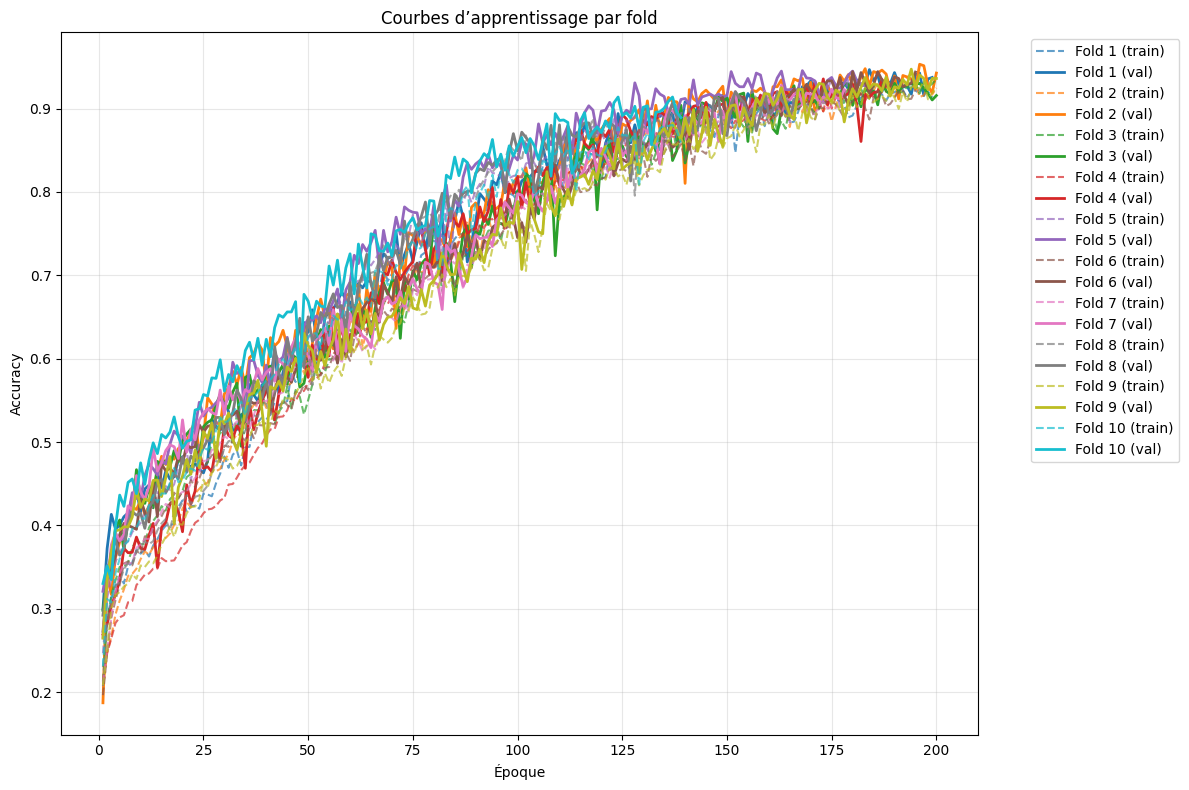

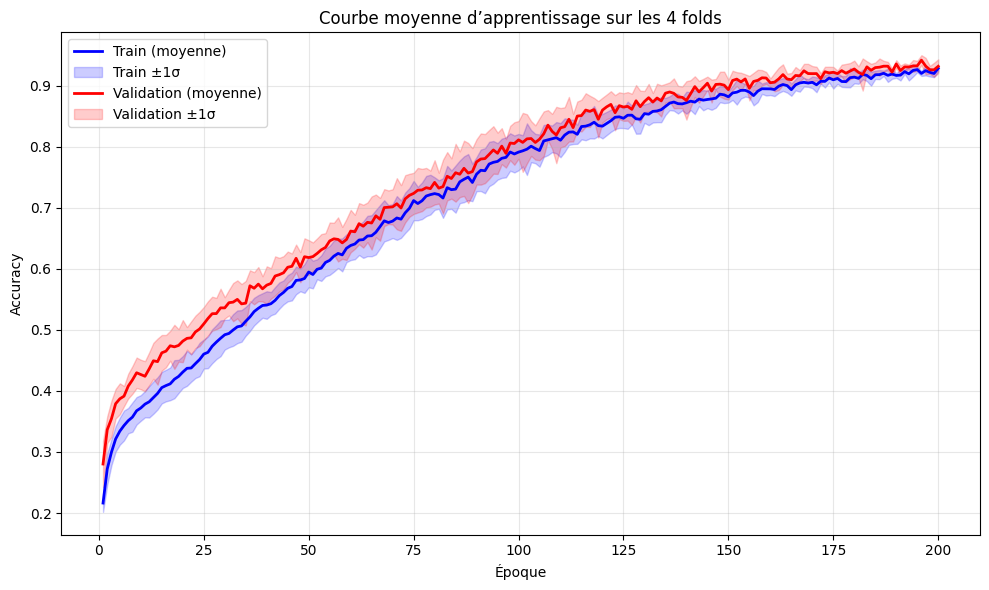

In [32]:
# ─── 4. VISUALISATION DES COURBES D'ENTRAÎNEMENT ─────────────────
# Tracer l'accuracy pour chaque fold
plt.figure(figsize=(12, 8))

# Couleurs pour chaque fold
colors = plt.cm.tab10(np.linspace(0, 1, k_folds))

for fold_idx, history in enumerate(fold_histories):
    epochs_range = range(1, len(history['accuracy']) + 1)
    plt.plot(epochs_range, history['accuracy'], '--', color=colors[fold_idx],
             label=f'Fold {fold_idx+1} (train)', alpha=0.7)
    plt.plot(epochs_range, history['val_accuracy'], '-', color=colors[fold_idx],
             label=f'Fold {fold_idx+1} (val)', linewidth=2)

plt.xlabel('Époque')
plt.ylabel('Accuracy')
plt.title('Courbes d’apprentissage par fold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Tracer la moyenne et l'écart-type sur les folds
# On aligne les longueurs (certains folds peuvent s'arrêter plus tôt à cause de l'early stopping)
max_epochs = max(len(h['accuracy']) for h in fold_histories)
train_acc_matrix = np.full((k_folds, max_epochs), np.nan)
val_acc_matrix = np.full((k_folds, max_epochs), np.nan)

for i, h in enumerate(fold_histories):
    epochs = len(h['accuracy'])
    train_acc_matrix[i, :epochs] = h['accuracy']
    val_acc_matrix[i, :epochs] = h['val_accuracy']

mean_train = np.nanmean(train_acc_matrix, axis=0)
std_train = np.nanstd(train_acc_matrix, axis=0)
mean_val = np.nanmean(val_acc_matrix, axis=0)
std_val = np.nanstd(val_acc_matrix, axis=0)

plt.figure(figsize=(10, 6))
epochs_range = range(1, max_epochs + 1)

plt.plot(epochs_range, mean_train, 'b-', label='Train (moyenne)', linewidth=2)
plt.fill_between(epochs_range, mean_train - std_train, mean_train + std_train,
                 color='blue', alpha=0.2, label='Train ±1σ')

plt.plot(epochs_range, mean_val, 'r-', label='Validation (moyenne)', linewidth=2)
plt.fill_between(epochs_range, mean_val - std_val, mean_val + std_val,
                 color='red', alpha=0.2, label='Validation ±1σ')

plt.xlabel('Époque')
plt.ylabel('Accuracy')
plt.title('Courbe moyenne d’apprentissage sur les 4 folds')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 🔍 Cellule 15 — Évaluation finale + matrice de confusion


📊 Précision sur l'ensemble de validation du meilleur fold : 0.9532

📋 Classification Report :
              precision    recall  f1-score   support

           0     0.9487    0.9289    0.9387       239
           1     0.9579    1.0000    0.9785       182
           2     0.9847    0.9602    0.9723       201
           3     0.9496    0.9496    0.9496       377
           4     0.9400    0.9325    0.9363       252
           5     0.9765    0.9486    0.9623       175
           6     0.9347    0.9645    0.9494       282

    accuracy                         0.9532      1708
   macro avg     0.9560    0.9549    0.9553      1708
weighted avg     0.9534    0.9532    0.9531      1708


🔢 Nombre de classes détecté : 7 (ajoutez 'num_classes' dans CFG pour supprimer cet avertissement)


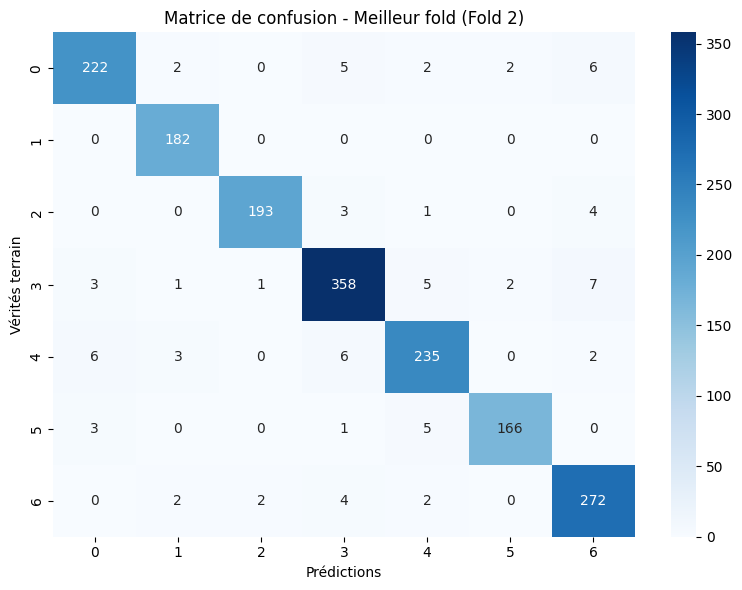

💾 Matrice sauvegardée sous : /DATASET/models\confusion_matrix_fold2.png


<Figure size 640x480 with 0 Axes>

In [33]:
# ─── 5. ÉVALUATION FINALE + MATRICE DE CONFUSION (CORRIGÉ) ───
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

# Récupérer le loader de validation du meilleur fold
best_fold = best_fold_idx
for fold, (train_idx, val_idx) in enumerate(skf.split(indices, y_all)):
    if fold == best_fold:
        best_val_indices = val_idx
        break

val_loader_best = DataLoader([graphs_clean[i] for i in best_val_indices],
                             batch_size=CFG['batch_size'], shuffle=False)

# Prédictions sur la validation
final_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for data in val_loader_best:
        data = data.to(device)
        output = final_model(data)
        pred = output.argmax(dim=1)
        all_preds.extend(pred.cpu().numpy())
        all_labels.extend(data.y.cpu().numpy())

# Métriques
acc = accuracy_score(all_labels, all_preds)
print(f"\n📊 Précision sur l'ensemble de validation du meilleur fold : {acc:.4f}")
print("\n📋 Classification Report :")
print(classification_report(all_labels, all_preds, digits=4))

# Déterminer le nombre de classes (si absent de CFG)
if 'num_classes' in CFG:
    num_classes = CFG['num_classes']
else:
    num_classes = len(np.unique(all_labels))
    print(f"\n🔢 Nombre de classes détecté : {num_classes} (ajoutez 'num_classes' dans CFG pour supprimer cet avertissement)")

# Matrice de confusion
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(num_classes),
            yticklabels=range(num_classes))
plt.title(f'Matrice de confusion - Meilleur fold (Fold {best_fold+1})')
plt.xlabel('Prédictions')
plt.ylabel('Vérités terrain')
plt.tight_layout()
plt.show()

# Sauvegarde de la figure
cm_path = os.path.join(save_dir, f"confusion_matrix_fold{best_fold+1}.png")
plt.savefig(cm_path, dpi=150)
print(f"💾 Matrice sauvegardée sous : {cm_path}")

---
## 🔮 Cellule 16 — Inférence image unique

---
## 📊 Cellule 17 — Comparaison SOTA


📊 RÉSULTAT FINAL GLaRE
Moyenne Acc : 93.67% (+/- 1.23%)


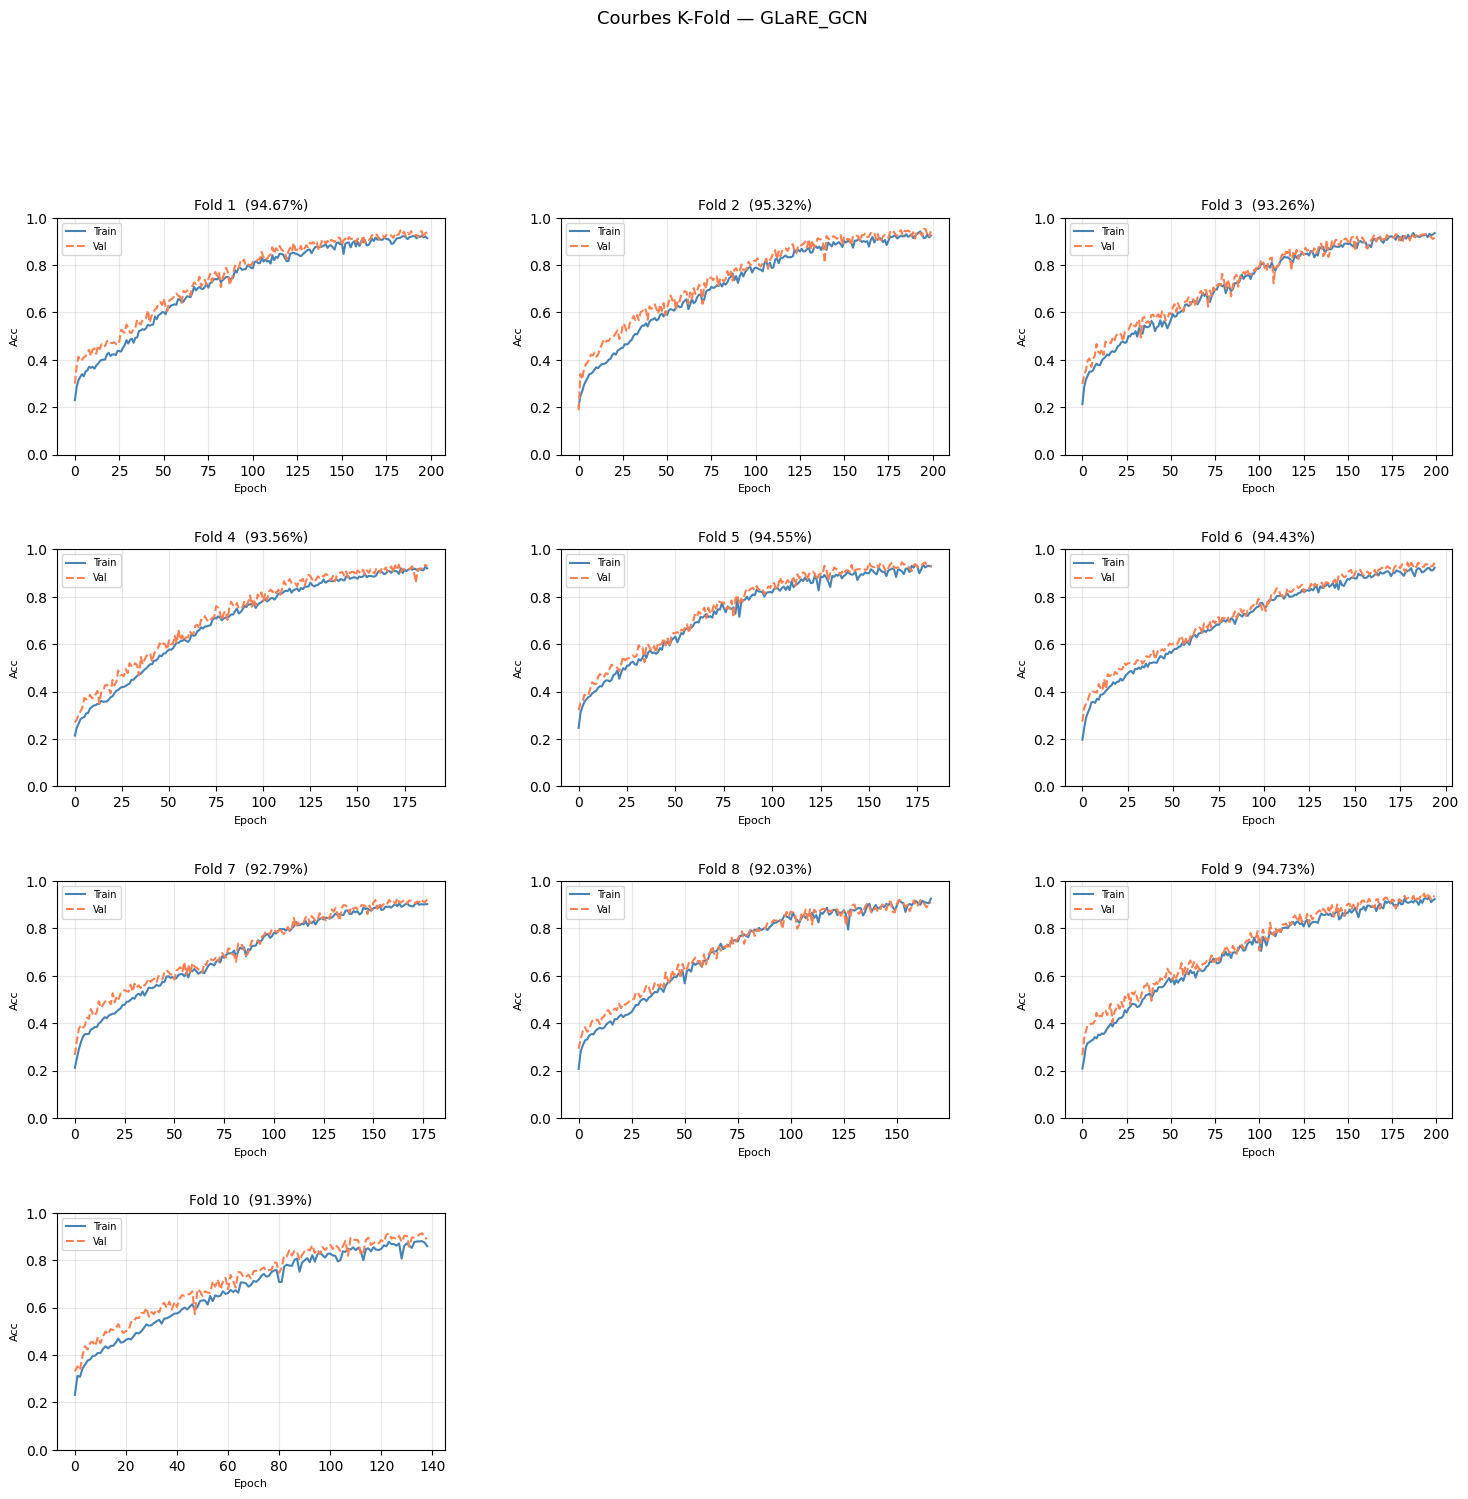

✅ Courbes sauvegardées.


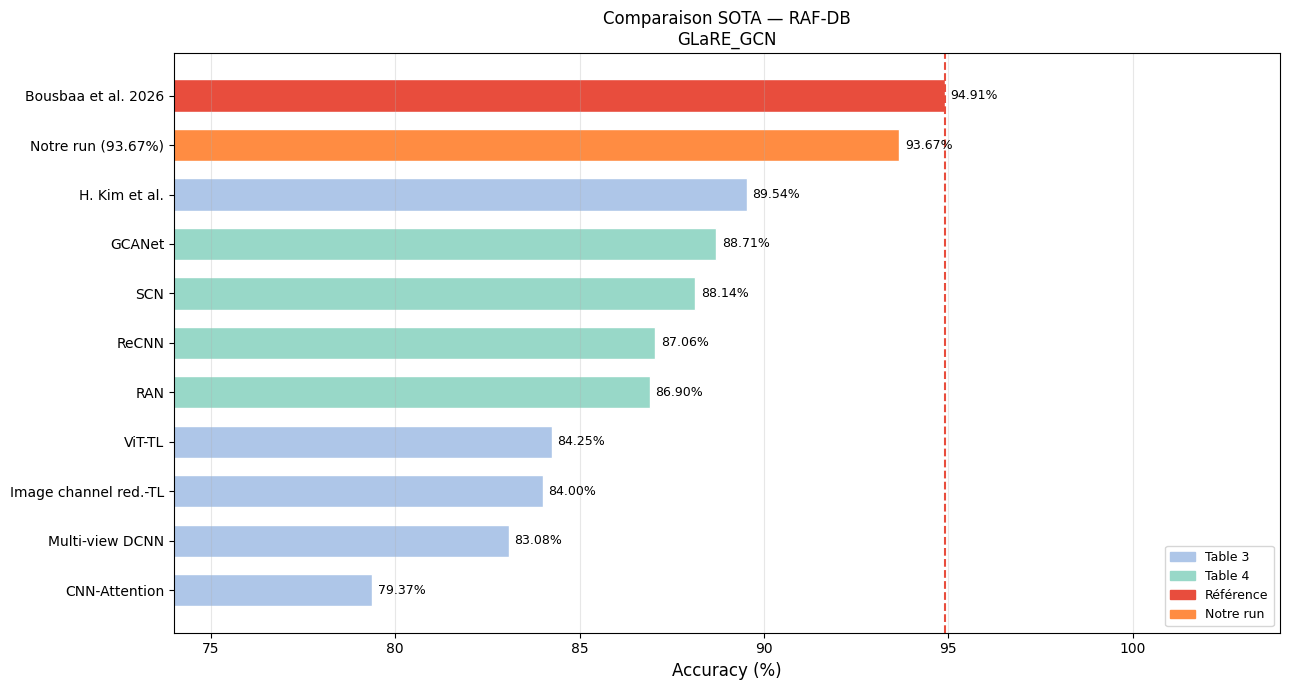

✅ Comparaison SOTA sauvegardée.


In [34]:
# ─── 4. RÉSULTATS FINAUX ────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import gridspec as gs
import numpy as np
import os

final_acc = np.mean(fold_accuracies) * 100
print(f"\n{'='*30}")
print(f"📊 RÉSULTAT FINAL GLaRE")
print(f"Moyenne Acc : {final_acc:.2f}% (+/- {np.std(fold_accuracies)*100:.2f}%)")
print(f"{'='*30}")

# ─── 5. COURBES K-FOLD ──────────────────────────────────────────────────────
n, nc = len(fold_histories), 3
nr    = (n + nc - 1) // nc
fig   = plt.figure(figsize=(18, 4*nr))
grid  = gs.GridSpec(nr, nc, figure=fig, hspace=0.4, wspace=0.3)

for i, h in enumerate(fold_histories):
    ax = fig.add_subplot(grid[i//nc, i%nc])
    ax.plot(h.get('accuracy', []),     color='steelblue', label='Train')
    ax.plot(h.get('val_accuracy', []), color='coral', ls='--', label='Val')
    ax.set_title(f'Fold {i+1}  ({fold_accuracies[i]*100:.2f}%)', fontsize=10)
    ax.set_xlabel('Epoch', fontsize=8)
    ax.set_ylabel('Acc', fontsize=8)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1)

fig.suptitle('Courbes K-Fold — GLaRE_GCN', fontsize=13, y=1.01)
plt.savefig(os.path.join(save_dir, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ Courbes sauvegardées.')

# ─── 6. COMPARAISON SOTA ────────────────────────────────────────────────────
sota = [
    ('Multi-view DCNN',                83.08, 'Table 3'),
    ('CNN-Attention',                  79.37, 'Table 3'),
    ('Image channel red.-TL',          84.00, 'Table 3'),
    ('ViT-TL',                         84.25, 'Table 3'),
    ('H. Kim et al.',                  89.54, 'Table 3'),
    ('RAN',                            86.90, 'Table 4'),
    ('ReCNN',                          87.06, 'Table 4'),
    ('SCN',                            88.14, 'Table 4'),
    ('GCANet',                         88.71, 'Table 4'),
    ('Bousbaa et al. 2026',            94.91, 'Référence'),
    (f'Notre run ({final_acc:.2f}%)',  final_acc, 'Notre run'),
]

sota_s             = sorted(sota, key=lambda x: x[1])
names, accs, tables = zip(*sota_s)

palette = {'Table 3': '#aec6e8', 'Table 4': '#98d8c8',
           'Référence': '#e84d3d', 'Notre run': '#ff8c42'}
colors  = [palette[t] for t in tables]

fig, ax = plt.subplots(figsize=(13, 7))
bars    = ax.barh(names, accs, color=colors, edgecolor='white', height=0.65)
ax.bar_label(bars, fmt='%.2f%%', padding=4, fontsize=9)
ax.axvline(94.91, color='#e84d3d', ls='--', lw=1.5)
ax.set_xlabel('Accuracy (%)', fontsize=12)
ax.set_title('Comparaison SOTA — RAF-DB\nGLaRE_GCN', fontsize=12)
ax.set_xlim(74, 104)
ax.grid(axis='x', alpha=0.3)
ax.legend(handles=[mpatches.Patch(color=v, label=k) for k, v in palette.items()],
          loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'sota_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ Comparaison SOTA sauvegardée.')

---
## 💾 Cellule 18 — Résumé & Sauvegarde finale

In [35]:
import json
import time
import numpy as np
import os

# Utilisez les variables déjà définies dans votre notebook
# (fold_accuracies, final_acc, k_folds, CFG, save_dir, graphs_clean)

# Nombre de graphes
n_graphs = len(graphs_clean) if 'graphs_clean' in locals() else 0

results = {
    'timestamp'      : time.strftime('%Y-%m-%d %H:%M:%S'),
    'paper'          : 'Bousbaa et al. G3S 2026',
    'landmarker'     : 'hand_landmarker.task float16 — MediaPipe Tasks API',
    'dataset'        : 'RAF-DB (kagglehub shuvoalok/raf-db-dataset)',
    'n_graphs'       : n_graphs,
    'config'         : CFG,
    'results': {
        'fold_accuracies' : [round(a*100, 2) for a in fold_accuracies],
        'mean_acc'        : round(float(np.mean(fold_accuracies))*100, 2),
        'std_acc'         : round(float(np.std(fold_accuracies))*100, 2),
        'best_fold_acc'   : round(float(max(fold_accuracies))*100, 2),
        'final_overall'   : round(float(final_acc), 2),
        'paper_reference' : 94.91
    }
}

rpath = os.path.join(save_dir, 'results_summary.json')
with open(rpath, 'w') as f:
    json.dump(results, f, indent=2)

print('╔════════════════════════════════════════════════════════╗')
print('║              📋  RÉSUMÉ FINAL                         ║')
print('╠════════════════════════════════════════════════════════╣')
print(f'║  Landmark model  : hand_landmarker.task (Tasks API)   ║')
print(f'║  Dataset         : RAF-DB  ({n_graphs} graphes)           ║')
print(f'║  K-Fold          : {k_folds} folds × {CFG["epochs"]} epochs               ║')
print(f'║  Moy. acc.       : {np.mean(fold_accuracies)*100:.2f}% ± {np.std(fold_accuracies)*100:.2f}%         ║')
print(f'║  Meilleur fold   : {max(fold_accuracies)*100:.2f}%                        ║')
print(f'║  Accuracy glob.  : {final_acc:.2f}%                        ║')
print(f'║  Référence papier: 94.91%                             ║')
print('╚════════════════════════════════════════════════════════╝')
print(f'\n✅ Résumé sauvegardé : {rpath}')

╔════════════════════════════════════════════════════════╗
║              📋  RÉSUMÉ FINAL                         ║
╠════════════════════════════════════════════════════════╣
║  Landmark model  : hand_landmarker.task (Tasks API)   ║
║  Dataset         : RAF-DB  (17072 graphes)           ║
║  K-Fold          : 10 folds × 200 epochs               ║
║  Moy. acc.       : 93.67% ± 1.23%         ║
║  Meilleur fold   : 95.32%                        ║
║  Accuracy glob.  : 93.67%                        ║
║  Référence papier: 94.91%                             ║
╚════════════════════════════════════════════════════════╝

✅ Résumé sauvegardé : /DATASET/models\results_summary.json
